<a href="https://colab.research.google.com/github/sitizaniahuny/step-1-BPPN-skripsi-/blob/main/step_2_Ver_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [185]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
warnings.filterwarnings('ignore', category=ConvergenceWarning)
RANDOM_STATE = 123
PASS_FILE = '/content/passengers.xlsx'
CAL_FILE = '/content/kalender.xlsx'

for name, path in [('penumpang', PASS_FILE), ('kalender', CAL_FILE)]:
    if not os.path.exists(path):
        alt = os.path.basename(path)
        if os.path.exists(alt):
            if name == 'penumpang': PASS_FILE = alt
            else: CAL_FILE = alt
        else: raise FileNotFoundError(f'Berkas {name} tidak ditemukan: {path}; upload dahulu ke Colab.')
print('Penumpang:',PASS_FILE, '\nKalender:', CAL_FILE)

Penumpang: /content/passengers.xlsx 
Kalender: /content/kalender.xlsx


pick 5 stations (Yogyakarta, Lempuyangan, Purwosari, Solo Balapan, Klaten)

In [186]:
STATIONS = ['Yogyakarta','Lempuyangan','Purwosari','Solo Balapan','Klaten']
p = pd.read_excel(PASS_FILE)
assert {'Station','Month','Passengers'}.issubset(p.columns), p.columns.tolist()
p = p[['Station','Month','Passengers']].copy()
p['Station'] = p['Station'].astype(str).str.strip()
p = p.loc[p['Station'].isin(STATIONS)].copy()

convert month to date (semua jadi per tgl 1; 01MonthYear)

In [187]:
p['Month'] = pd.to_datetime(p['Month'], errors='coerce').dt.to_period('M').dt.to_timestamp()

convert passengers to numeric

In [188]:
p['Passengers'] = pd.to_numeric(p['Passengers'],errors='coerce')

make sure semua months valid, cari baris yg berkombinasi stasiun dan bulan yg berulang, dropna, dan make sure gaada penumpang yg nilainya negatif

In [189]:
assert p['Month'].notna().all(), 'Ada tanggal tidak valid'
assert not p.duplicated(['Station','Month']).any(), 'Ada duplikat'
assert (p['Passengers'].dropna() >= 0).all(), 'Jumlah penumpang gabisa negatif'

mengurutkan tanggal, make stations and months as index,

In [190]:
months = pd.date_range('2018-01-01','2026-01-01',freq='MS')
expected = pd.MultiIndex.from_product([STATIONS, months],names=['Station','Month'])
p = p.set_index(['Station','Month']).reindex(expected).reset_index()

dari Januari 2018-Januari 2026 = 97 months. maka 5 stations * 97 months = 485 observasi

In [191]:
print('Jumlah observasi yang seharusnya:',len(expected),' | missing:',p.Passengers.isna().sum())
assert p.Passengers.notna().all(), 'Lima stasiun terpilih seharusnya lengkap, cek'
display(p.groupby('Station').agg(n=('Passengers','size'),minimum=('Passengers','min'),rata_rata=('Passengers','mean')).round(1))

Jumlah observasi yang seharusnya: 485  | missing: 0


,n,minimum,rata_rata
Station,,,
Klaten,97,1229.0,23081.4
Lempuyangan,97,2707.0,104815.6
Purwosari,97,2043.0,25247.9
Solo Balapan,97,7084.0,114609.5
Yogyakarta,97,6893.0,212257.5


##**kalender**

rename

In [192]:
k = pd.read_excel(CAL_FILE, sheet_name='Kalender Bulanan')
rename = {'Tahun':'year','Bulan (angka)':'month', 'Jml Hari Libur Nasional':'n_libur','Jml Hari Cuti Bersama':'n_cuti'}
k = k.rename(columns=rename)

In [193]:
calendar_cols = ['n_libur','n_cuti','dummy_lebaran','dummy_nataru']
required = ['year','month']+calendar_cols
assert set(required).issubset(k.columns), ('Kolom kalender',k.columns.tolist())
for col in required: k[col] = pd.to_numeric(k[col],errors='coerce')
k = k.loc[(k.year>=2018)&((k.year<2026)|((k.year==2026)&(k.month==1)))].copy()

k['Month'] = pd.to_datetime(dict(year=k.year.astype(int),month=k.month.astype(int),day=1))
df = p.merge(k[['Month']+calendar_cols],on='Month',how='left',validate='many_to_one')
assert df[calendar_cols].notna().all().all(), 'Ada bulan penumpang tidak punya data kalender'
print('Jumlah baris tergabung',len(df),'| rentang',df.Month.min().date(),df.Month.max().date())
display(df.head())

Jumlah baris tergabung 485 | rentang 2018-01-01 2026-01-01


,Station,Month,Passengers,n_libur,n_cuti,dummy_lebaran,dummy_nataru
0,Yogyakarta,2018-01-01,291156.0,1,0,0.0,1.0
1,Yogyakarta,2018-02-01,272410.0,1,0,0.0,0.0
2,Yogyakarta,2018-03-01,306158.0,2,0,0.0,0.0
3,Yogyakarta,2018-04-01,309101.0,1,0,0.0,0.0
4,Yogyakarta,2018-05-01,270981.0,3,0,0.0,0.0


make sure ga ada Na, gaada kombinasi year & months yg double, jumlah cutlibur ga ada yg negatif

In [194]:
assert k[required].notna().all().all(), 'Ada kalender kosong pada bulan yang dianalisis'
assert not k.duplicated(['year','month']).any(), 'Tahun-bulan kalender ganda'
assert k[calendar_cols].ge(0).all().all(), 'Tidak boleh negatif'

kalender dibuat jd format date, merge two datasets

In [195]:
k['Month'] = pd.to_datetime(dict(year=k.year.astype(int),month=k.month.astype(int),day=1))
df = p.merge(k[['Month']+calendar_cols],on='Month',how='left',validate='many_to_one')
assert df[calendar_cols].notna().all().all(), 'Ada bulan penumpang tidak punya data kalender'
print('Jumlah baris tergabung',len(df),'| rentang',df.Month.min().date(),df.Month.max().date())
display(df.head())

Jumlah baris tergabung 485 | rentang 2018-01-01 2026-01-01


,Station,Month,Passengers,n_libur,n_cuti,dummy_lebaran,dummy_nataru
0,Yogyakarta,2018-01-01,291156.0,1,0,0.0,1.0
1,Yogyakarta,2018-02-01,272410.0,1,0,0.0,0.0
2,Yogyakarta,2018-03-01,306158.0,2,0,0.0,0.0
3,Yogyakarta,2018-04-01,309101.0,1,0,0.0,0.0
4,Yogyakarta,2018-05-01,270981.0,3,0,0.0,0.0


#**buat fitur LAG**

lag 1 = passengers April 2025,
lag 2 = passengers Maret 2025,
lag 3 = passengers Feb 2025,
lag 6 = passengers Nov 2024,
lag 12 = passengers Mei 2024

In [196]:
df = df.sort_values(['Station','Month']).reset_index(drop=True)
for lag in [1,2,3,6,12]:
    df[f'lag_{lag}'] = df.groupby('Station')['Passengers'].shift(lag)

month_num as nomor month dari 1 sampai 12, dijadikan sin dan cos krn desember dan januari in number adalah 12 dan 1, maka dijadikan sin cos biar model menangkap pola bahwa kedua bulan tsb berdekatan dalam siklus

In [197]:
df['month_num'] = df.Month.dt.month
df['month_sin'] = np.sin(2*np.pi*df.month_num/12)
df['month_cos'] = np.cos(2*np.pi*df.month_num/12)
df['days_in_month'] = df.Month.dt.days_in_month
df['time_index'] = (df.Month.dt.year-2018)*12 + df.Month.dt.month-1

month_sin = sin (2 phi m / 12)


month_cos = cos (2 phi m / 12)

In [198]:
#dipakai as fitur kalender sederhana, tanpa asumsi koreksi tanggal harian
df['total_libur_cuti'] = df['n_libur']+df['n_cuti']

##**cek lag before split**

semua lag dibuat dari deret asli per stasiun SEBELUM observasi awal disaring. krn lag terbesar = 12 bulan, 12 bulan pertama per stasiun belum ada seluruh fitur.


In [199]:
lag_cols = ['lag_1','lag_2','lag_3','lag_6','lag_12']
print('Sebelum penyaringan:', len(df), 'baris')
print('NaN pada masing-masing lag:')
print(df[lag_cols].isna().sum().to_string())

#Baris yang tidak memiliki riwayat 12 bulan belum layak untuk BPPN.
#bukan mengubah/mengimputasi jumlah penumpang: baris asli tetap tersimpan di p.
df = df.dropna(subset=lag_cols).copy().reset_index(drop=True)

Sebelum penyaringan: 485 baris
NaN pada masing-masing lag:
lag_1      5
lag_2     10
lag_3     15
lag_6     30
lag_12    60


In [200]:
BASE = ['Station','lag_1','lag_2','lag_3','lag_6','lag_12','month_sin','month_cos','days_in_month']
FEATURE_SETS = {
    'Tanpa kalender': [],
    'Jumlah libur+cuti': ['n_libur','n_cuti'],
    'Jumlah + Lebaran Nataru': ['n_libur','n_cuti','dummy_lebaran','dummy_nataru']
}
all_predictors = list(dict.fromkeys(BASE + [c for extra in FEATURE_SETS.values() for c in extra]))
assert df[all_predictors].notna().all().all(), ("Ada fitur lain yang kosong", df[all_predictors].isna().sum())
assert df['Passengers'].notna().all(), 'Target masih memiliki missing value'
assert len(df) == 5*(97-12), 'Jumlah baris setelah lag 12 tidak sesuai asumsi data'
print('Setelah penyaringan:', len(df), 'baris; awal tiap stasiun:')
print(df.groupby('Station')['Month'].min().to_string())
print('NaN pada fitur akhir:', int(df[all_predictors].isna().sum().sum()))

Setelah penyaringan: 425 baris; awal tiap stasiun:
Station
Klaten         2019-01-01
Lempuyangan    2019-01-01
Purwosari      2019-01-01
Solo Balapan   2019-01-01
Yogyakarta     2019-01-01
NaN pada fitur akhir: 0


##**Split**

MAE/RMSE dinyatakan dalam penumpang, MAPE/WAPE berupa %, macro MASE adalah rata-rata MASE per stasiun.

In [201]:
TEST_START = pd.Timestamp('2025-01-01')
END_TEST = pd.Timestamp('2026-01-01')
val_periods = [(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-01')),
               (pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-01'))]
train_final = df.loc[df.Month < TEST_START].copy()
test = df.loc[(df.Month >= TEST_START)&(df.Month<=END_TEST)].copy()
assert len(test)==13*5 and test.Passengers.gt(0).all()

def score(y, pred):
    y=np.asarray(y,dtype=float); pred=np.asarray(pred,dtype=float)
    return {'MAE':mean_absolute_error(y,pred),
            'RMSE':np.sqrt(mean_squared_error(y,pred)),
            'MAPE_pct':100*np.mean(np.abs(y-pred)/y),
            'WAPE_pct':100*np.sum(np.abs(y-pred))/np.sum(y)}

def station_macro_mase(observations, predictions, training):
    values=[]
    for station,g in observations.assign(prediction=np.asarray(predictions)).groupby('Station'):
        history=training.loc[training.Station==station].sort_values('Month').Passengers.to_numpy(dtype=float)
        denom=(float(np.mean(np.abs(history[12:]-history[:-12]))) if len(history)>=13 else np.nan)
        if not np.isfinite(denom) or denom<=0:
            values.append(np.nan)
        else:
            values.append(np.mean(np.abs(g.Passengers-g.prediction))/denom)
    return float(np.mean(values)) if all(np.isfinite(values)) else np.nan

def diagnostics(observations,pred,training):
    metrics=score(observations.Passengers,pred)
    metrics['macro_MASE']=station_macro_mase(observations,pred,training)
    return metrics
print('Pelatihan final:',len(train_final),'| test:',len(test))

Pelatihan final: 360 | test: 65


##**modeling dan tuning**

jumlah neuron dan learning rate nya di compare secara terbatas, semua scaler nya dipasang di pipeline, jd belajar dari data training masing-masing fold nya. masing-masing fold:
1. fold validasi pertama = model di train dgn data sebelum 2023, trs di eval di data 2023.
2. fold validasi kedua = mode di train dgn data sebelum 2023 (lebih luas drpd fold pertama), trs di eval di data 2024.

jd model ga di train pake data future untuk predict masa lalu

In [202]:
def make_model(algorithm, cols, config):
    numeric=[c for c in cols if c!='Station']
    prep=ColumnTransformer([
        ('station',OneHotEncoder(handle_unknown='ignore'),['Station']),
        ('numeric',StandardScaler(),numeric)])
    if algorithm!='BPPN': raise ValueError(algorithm)
    est=MLPRegressor(hidden_layer_sizes=config['hidden'],
                 learning_rate_init=config['lr'],
                 alpha=config['alpha'],
                 max_iter=1200,
                 solver='adam',
                 activation='relu',
                 early_stopping=False,
                 random_state=RANDOM_STATE,
                 tol=1e-4,
                 n_iter_no_change=70)

    reg=TransformedTargetRegressor(regressor=est,transformer=StandardScaler())
    return Pipeline([('prep',prep),('model',reg)])

CONFIGS={'BPPN':[{'hidden':h,'lr':lr,'alpha':0.01}
                 for h,lr in [((8,4),0.001),((16,8),0.001),((16,8),0.01)]]}

early_stopping off biar mempertahankan urutan waktu pada data time series nya

##**rolling origin validation**

untuk tiap tahun validasi, model hanya dilatih dari tahun-tahun sebelumnya. rata2 macro MASE terendah yg nanti dipilih pada 2023 & 2024. periode test 2025 & 2026 ga di ikutin di pencarian fitur/config

In [203]:
from itertools import product
rows=[]
for algo, configs in CONFIGS.items():
    for set_name, extra in FEATURE_SETS.items():
        cols=BASE+extra
        for config in configs:
            fold_scores=[]
            for start,end in val_periods:
                tr=df.loc[df.Month<start].copy()
                va=df.loc[(df.Month>=start)&(df.Month<=end)].copy()
                model=make_model(algo,cols,config)
                model.fit(tr[cols],tr.Passengers)
                raw=model.predict(va[cols])
                pred=np.maximum(raw,0)
                m=diagnostics(va,pred,tr)
                fold_scores.append(m)
            rows.append({'model':algo,'fitur':set_name,'config':repr(config),
                         'score_macro_MASE':np.mean([f['macro_MASE'] for f in fold_scores]),
                         'val2023_MASE':fold_scores[0]['macro_MASE'],
                         'val2024_MASE':fold_scores[1]['macro_MASE'],
                         'val_MAPE_mean':np.mean([f['MAPE_pct'] for f in fold_scores]),
                         '_config':config,'_cols':cols})
results=pd.DataFrame(rows).sort_values(['model','score_macro_MASE']).reset_index(drop=True)
print('Semua kandidat dan hasil validasinya:')
display(results.drop(columns=['_config','_cols']).round(4))
selected={}
for algo in CONFIGS:
    top=results.loc[results.model==algo].sort_values('score_macro_MASE').iloc[0]
    selected[algo]=top
    print(f'{algo}: fitur={top.fitur}, config={top.config}, MASE validasi={top.score_macro_MASE:.4f}')

Semua kandidat dan hasil validasinya:


,model,fitur,config,score_macro_MASE,val2023_MASE,val2024_MASE,val_MAPE_mean
0,BPPN,Jumlah + Lebaran Nataru,"{'hidden': (8, 4), 'lr': 0.001, 'alpha': 0.01}",0.2594,0.2629,0.2560,16.2226
1,BPPN,Jumlah libur+cuti,"{'hidden': (16, 8), 'lr': 0.01, 'alpha': 0.01}",0.3029,0.3330,0.2727,19.0356
2,BPPN,Tanpa kalender,"{'hidden': (16, 8), 'lr': 0.001, 'alpha': 0.01}",0.3038,0.2425,0.3652,18.4714
3,BPPN,Tanpa kalender,"{'hidden': (16, 8), 'lr': 0.01, 'alpha': 0.01}",0.3170,0.2913,0.3427,19.5604
4,BPPN,Jumlah libur+cuti,"{'hidden': (8, 4), 'lr': 0.001, 'alpha': 0.01}",0.3177,0.2732,0.3622,20.0639
5,BPPN,Tanpa kalender,"{'hidden': (8, 4), 'lr': 0.001, 'alpha': 0.01}",0.3310,0.2741,0.3880,19.8481
6,BPPN,Jumlah libur+cuti,"{'hidden': (16, 8), 'lr': 0.001, 'alpha': 0.01}",0.3783,0.3325,0.4241,24.5006
7,BPPN,Jumlah + Lebaran Nataru,"{'hidden': (16, 8), 'lr': 0.01, 'alpha': 0.01}",0.3941,0.4474,0.3408,26.3536
8,BPPN,Jumlah + Lebaran Nataru,"{'hidden': (16, 8), 'lr': 0.001, 'alpha': 0.01}",0.4686,0.5956,0.3415,30.7643


BPPN: fitur=Jumlah + Lebaran Nataru, config={'hidden': (8, 4), 'lr': 0.001, 'alpha': 0.01}, MASE validasi=0.2594


MASE terendah = terbaik.
1. dari hasil tsb berarti pada data validasi 2023-2024, config dgn 2 hidden layer 8 dan 4 neuron, learning rate 0.001 dgn fitur kalender lengkap memberikan nilai MASE rata-rata terbaik diantara yg lain
2. hasil tsb hanya hasil kinerja pada validasi, blm tentu bagus untuk predict future sblm lihat hasil test

##**re-train model final dan evaluasi pada test**

best config dari hasil sebelumnya (validation) di train ulang dgn semua observasi yg ada sampai Dec 2024. SN buat prediksi pake lag_12 tanpa variabel kalender.

In [204]:
prediction=test[['Station','Month','Passengers','lag_12']].copy()
prediction['Seasonal Naive']=prediction.lag_12.to_numpy(dtype=float)
final_models={}

#re-train model BPPN
for algo in ['BPPN']:
    r=selected[algo]
    cols=r['_cols']; config=r['_config']
    model=make_model(algo,cols,config)
    model.fit(train_final[cols],train_final.Passengers)
    raw=model.predict(test[cols])
    prediction[f'{algo} (mentah)']=raw
    prediction[algo]=np.maximum(raw,0)
    final_models[algo]=model
summary=[]
for name in ['Seasonal Naive'] + ['BPPN']:
    m=diagnostics(test,prediction[name],train_final)
    summary.append({'Model':name,**m})
summary=pd.DataFrame(summary).sort_values('macro_MASE')
print('Peringkat test, hanya untuk pelaporan (bukan tuning):')
display(summary.round(4))
print('Jumlah prediksi mentah negatif:', {a:int((prediction[f'{a} (mentah)']<0).sum()) for a in ['BPPN']})

Peringkat test, hanya untuk pelaporan (bukan tuning):


,Model,MAE,RMSE,MAPE_pct,WAPE_pct,macro_MASE
0,Seasonal Naive,11705.1385,15714.5031,13.0514,10.4487,0.2803
1,BPPN,15148.3026,21136.2395,17.0607,13.5223,0.3601


Jumlah prediksi mentah negatif: {'BPPN': 0}


##**compare antarstasiun dan bulan**

In [205]:
station_rows=[]
for name in ['Seasonal Naive'] + ['BPPN']:
    for st,g in prediction.groupby('Station'):
        station_rows.append({'Model':name,'Station':st,**score(g.Passengers,g[name])})
by_station=pd.DataFrame(station_rows).sort_values(['Station','Model'])
display(by_station.round(3))
long=[]
for name in ['Seasonal Naive'] + ['BPPN']:
    t=prediction[['Station','Month','Passengers',name]].copy().rename(columns={name:'Forecast'})
    t['Model']=name
    t['Error']=t.Passengers-t.Forecast
    t['APE_pct']=100*np.abs(t.Error)/t.Passengers
    long.append(t)
errors=pd.concat(long,ignore_index=True)
print('15 kesalahan persentase terbesar:')
display(errors.sort_values('APE_pct',ascending=False).head(15).round(2))

,Model,Station,MAE,RMSE,MAPE_pct,WAPE_pct
5,BPPN,Klaten,4837.710,6312.008,20.220,19.091
0,Seasonal Naive,Klaten,3630.077,5006.088,14.247,14.326
6,BPPN,Lempuyangan,21904.510,26665.507,18.246,17.538
1,Seasonal Naive,Lempuyangan,10083.615,11243.489,8.368,8.073
7,BPPN,Purwosari,4732.897,5709.468,21.505,20.772
2,Seasonal Naive,Purwosari,4158.923,4827.187,18.753,18.253
8,BPPN,Solo Balapan,18295.991,22873.224,15.070,13.931
3,Seasonal Naive,Solo Balapan,22058.923,24133.532,16.652,16.796
9,BPPN,Yogyakarta,25970.404,30447.167,10.263,10.154
4,Seasonal Naive,Yogyakarta,18594.154,21852.277,7.239,7.270


15 kesalahan persentase terbesar:


,Station,Month,Passengers,Forecast,Model,Error,APE_pct
69,Klaten,2025-05-01,21175.0,33376.20,BPPN,-12201.20,57.62
95,Purwosari,2025-05-01,19293.0,29431.34,BPPN,-10138.34,52.55
85,Lempuyangan,2025-08-01,122260.0,184759.33,BPPN,-62499.33,51.12
72,Klaten,2025-08-01,21487.0,31911.56,BPPN,-10424.56,48.52
3,Klaten,2025-04-01,31067.0,44905.00,Seasonal Naive,-13838.00,44.54
91,Purwosari,2025-01-01,23614.0,13196.78,BPPN,10417.22,44.11
74,Klaten,2025-10-01,21484.0,30744.17,BPPN,-9260.17,43.10
111,Solo Balapan,2025-08-01,121697.0,169417.56,BPPN,-47720.56,39.21
106,Solo Balapan,2025-03-01,105888.0,66006.99,BPPN,39881.01,37.66
29,Purwosari,2025-04-01,28051.0,37717.00,Seasonal Naive,-9666.00,34.46


##**visualisasi**

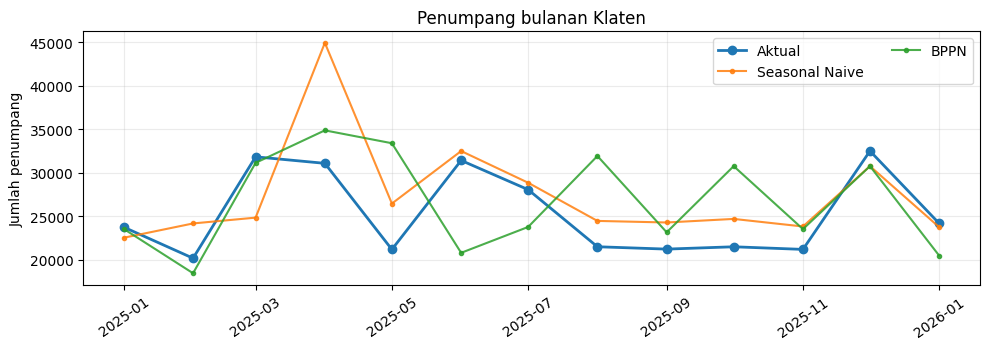

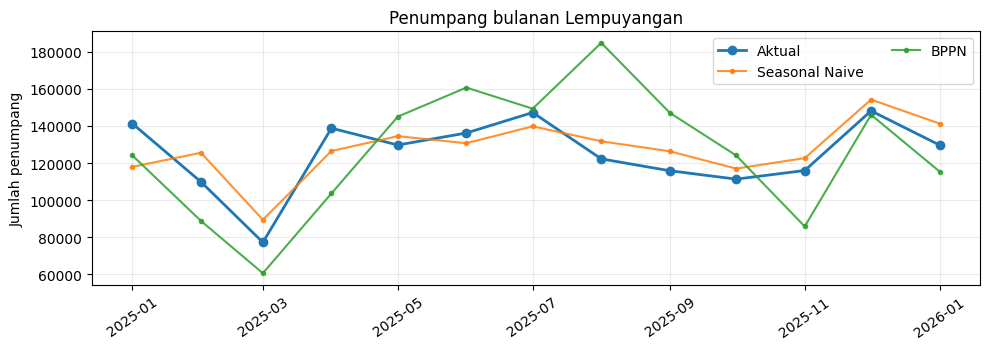

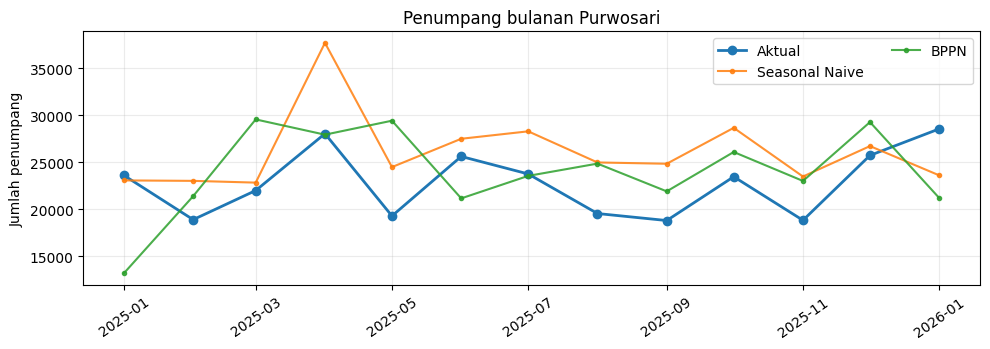

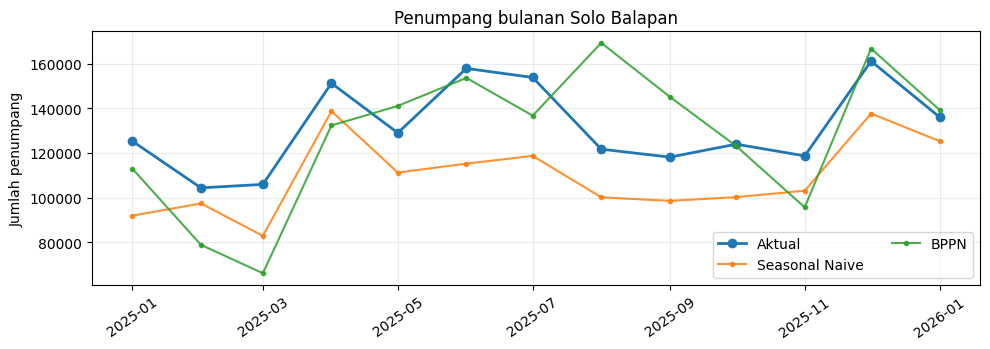

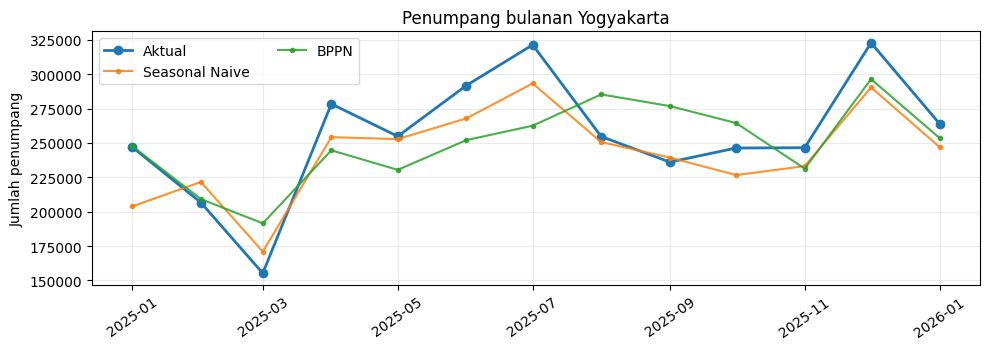

In [206]:
for station,g in prediction.groupby('Station'):
    g=g.sort_values('Month')
    fig,ax=plt.subplots(figsize=(10,3.6))
    ax.plot(g.Month,g.Passengers,label='Aktual',marker='o',linewidth=2)
    for name in ['Seasonal Naive'] + ['BPPN']:
        ax.plot(g.Month,g[name],label=name,marker='.',alpha=.85)
    ax.set_title('Penumpang bulanan '+station)
    ax.set_ylabel('Jumlah penumpang'); ax.grid(alpha=.25); ax.legend(ncol=2)
    plt.xticks(rotation=35); plt.tight_layout(); plt.show()

##**cek pandemi season dan 5 stations**

Deskripsi stasiun:


,n_bulan,rata_rata,minimum,maksimum
Station,,,,
Klaten,97,23081.4,1229.0,52077.0
Lempuyangan,97,104815.6,2707.0,190990.0
Purwosari,97,25247.9,2043.0,65347.0
Solo Balapan,97,114609.5,7084.0,280570.0
Yogyakarta,97,212257.5,6893.0,443473.0


Jumlah penumpang tahunan gabungan:


,Tahun,Passengers
0,2018,9086854.0
1,2019,9312812.0
2,2020,3217247.0
3,2021,1630516.0
4,2022,4153798.0
5,2023,5514623.0
6,2024,6363709.0
7,2025,6699240.0


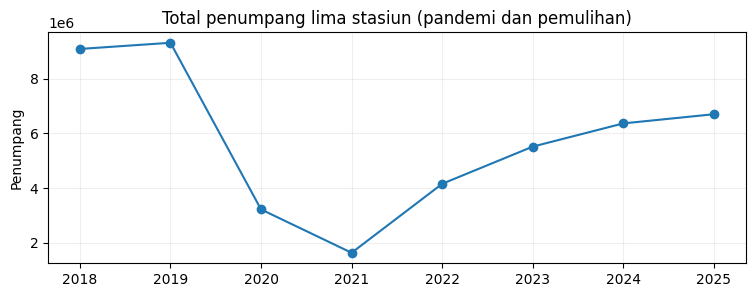

In [207]:
year_totals=(p.assign(Tahun=p.Month.dt.year)
               .query('Tahun < 2026').groupby('Tahun',as_index=False).Passengers.sum())
monthly_station=p.groupby('Station').agg(n_bulan=('Passengers','size'),
                         rata_rata=('Passengers','mean'),minimum=('Passengers','min'),
                         maksimum=('Passengers','max')).round(1)
print('Deskripsi stasiun:')
display(monthly_station)
print('Jumlah penumpang tahunan gabungan:')
display(year_totals)
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(year_totals.Tahun,year_totals.Passengers,marker='o')
ax.set_title('Total penumpang lima stasiun (pandemi dan pemulihan)')
ax.set_ylabel('Penumpang');ax.grid(alpha=.2);plt.show()

###**calendar check**

In [208]:
calendar_check=(k.groupby(['year'],as_index=False)
                 .agg(bulan_tersedia=('month','nunique'),hari_libur=('n_libur','sum'),
                      hari_cuti=('n_cuti','sum'),bulan_lebaran=('dummy_lebaran','sum'),
                      bulan_nataru=('dummy_nataru','sum')))
display(calendar_check)
print('Bulan dengan Lebaran menurut rekap SUMBER:')
display(k.loc[k.dummy_lebaran==1,['year','month','n_libur','n_cuti']])

,year,bulan_tersedia,hari_libur,hari_cuti,bulan_lebaran,bulan_nataru
0,2018,12,16,8,1.0,2.0
1,2019,12,16,4,1.0,2.0
2,2020,12,16,5,2.0,2.0
3,2021,12,16,1,1.0,2.0
4,2022,12,16,4,2.0,2.0
5,2023,12,16,8,1.0,2.0
6,2024,12,17,10,1.0,2.0
7,2025,12,17,11,2.0,2.0
8,2026,1,2,0,0.0,1.0


Bulan dengan Lebaran menurut rekap SUMBER:


,year,month,n_libur,n_cuti
5,2018,6,3,7
17,2019,6,3,3
28,2020,5,5,0
35,2020,12,1,2
40,2021,5,5,1
51,2022,4,1,1
52,2022,5,5,3
63,2023,4,3,4
75,2024,4,2,4
86,2025,3,2,1


##**uji pake calendar pada validation dgn parameter yg sama**

In [209]:
ablation_rows=[]
for algo in CONFIGS:
    conf=selected[algo]['_config']
    for feature_name,extra in FEATURE_SETS.items():
        cols=BASE+extra
        for start,end in val_periods:
            tr=df.loc[df.Month<start]
            va=df.loc[(df.Month>=start)&(df.Month<=end)]
            model=make_model(algo,cols,conf)
            model.fit(tr[cols],tr.Passengers)
            pred=np.maximum(model.predict(va[cols]),0)
            result=diagnostics(va,pred,tr)
            ablation_rows.append({'Model':algo,'Fitur':feature_name,
                'Fold':start.year,'MAE':result['MAE'],'MAPE_pct':result['MAPE_pct'],
                'macro_MASE':result['macro_MASE'], 'Konfigurasi tetap':repr(conf)})
ablation_val=pd.DataFrame(ablation_rows)
ablation_mean=(ablation_val.groupby(['Model','Fitur'],as_index=False)
               [['MAE','MAPE_pct','macro_MASE']].mean())
print('Pengaruh kalender pada VALIDASI, parameter model ditahan tetap:')
display(ablation_mean.sort_values(['Model','macro_MASE']).round(4))

Pengaruh kalender pada VALIDASI, parameter model ditahan tetap:


,Model,Fitur,MAE,MAPE_pct,macro_MASE
0,BPPN,Jumlah + Lebaran Nataru,13847.9725,16.2226,0.2594
1,BPPN,Jumlah libur+cuti,16043.6328,20.0639,0.3177
2,BPPN,Tanpa kalender,15425.5017,19.8481,0.3310


##**cek sensitivitas periode training**

In [210]:
window_rows=[]
for algo in CONFIGS:
    row=selected[algo]; conf=row['_config']; cols=row['_cols']
    for begin in ['2019-01-01','2022-01-01']:
        # 2019: setelah lag 12; 2022: tahap pemulihan, namun lag awal tetap dibentuk dari 2018-2021.
        for start,end in val_periods:
            tr=df.loc[(df.Month>=pd.Timestamp(begin))&(df.Month<start)]
            va=df.loc[(df.Month>=start)&(df.Month<=end)]
            if len(tr)<30:
                continue
            model=make_model(algo,cols,conf)
            model.fit(tr[cols],tr.Passengers)
            pred=np.maximum(model.predict(va[cols]),0)
            s=diagnostics(va,pred,tr)
            window_rows.append({'Model':algo,'Training mulai':begin,
                                'Validasi':start.year,'Jumlah training':len(tr),
                                'MAPE_pct':s['MAPE_pct'],'macro_MASE':s['macro_MASE'],
                                'Status MASE':'Terdefinisi' if np.isfinite(s['macro_MASE']) else 'Tidak terdefinisi: riwayat <13 bulan'})
window_val=pd.DataFrame(window_rows)
print('Sensitivitas hanya dilihat di VALIDASI:')
display(window_val.round(4))

Sensitivitas hanya dilihat di VALIDASI:


,Model,Training mulai,Validasi,Jumlah training,MAPE_pct,macro_MASE,Status MASE
0,BPPN,2019-01-01,2023,240,18.7673,0.2629,Terdefinisi
1,BPPN,2019-01-01,2024,300,13.6780,0.2560,Terdefinisi
2,BPPN,2022-01-01,2023,60,38.3583,NaN,Tidak terdefinisi: riwayat <13 bulan
3,BPPN,2022-01-01,2024,120,18.0877,0.7010,Terdefinisi


##**error check**

bulan dgn label lebaran/nataru adalah kelompok eval setelah modeling selesai. bukan sbg prediktor yg ditambah lg.

In [211]:
error_audit=errors.merge(df[['Station','Month','n_libur','n_cuti','dummy_lebaran','dummy_nataru']],
                         on=['Station','Month'],how='left',validate='many_to_one')
error_audit['bulan_libur_atau_cuti']=(error_audit.n_libur+error_audit.n_cuti)>0
error_audit['hari_raya']=((error_audit.dummy_lebaran==1)|(error_audit.dummy_nataru==1))
error_group=(error_audit.groupby(['Model','hari_raya'],as_index=False)
             .agg(n=('APE_pct','size'),rata_APE=('APE_pct','mean'),
                  MAE=('Error',lambda z:float(np.abs(z).mean()))))
print('Error berdasarkan label hari raya pada data sumber:')
display(error_group.round(3))
print('Prediksi dengan kesalahan persentase terbesar pada tiap model:')
display(error_audit.sort_values('APE_pct',ascending=False).groupby('Model',as_index=False).head(7).round(2))

Error berdasarkan label hari raya pada data sumber:


,Model,hari_raya,n,rata_APE,MAE
0,BPPN,False,40,19.234,16816.209
1,BPPN,True,25,13.583,12479.652
2,Seasonal Naive,False,40,13.044,10462.250
3,Seasonal Naive,True,25,13.063,13693.760


Prediksi dengan kesalahan persentase terbesar pada tiap model:


,Station,Month,Passengers,Forecast,Model,Error,APE_pct,n_libur,n_cuti,dummy_lebaran,dummy_nataru,bulan_libur_atau_cuti,hari_raya
69,Klaten,2025-05-01,21175.0,33376.20,BPPN,-12201.20,57.62,3,2,0.0,0.0,True,False
95,Purwosari,2025-05-01,19293.0,29431.34,BPPN,-10138.34,52.55,3,2,0.0,0.0,True,False
85,Lempuyangan,2025-08-01,122260.0,184759.33,BPPN,-62499.33,51.12,1,1,0.0,0.0,True,False
72,Klaten,2025-08-01,21487.0,31911.56,BPPN,-10424.56,48.52,1,1,0.0,0.0,True,False
3,Klaten,2025-04-01,31067.0,44905.00,Seasonal Naive,-13838.00,44.54,3,4,1.0,0.0,True,True
91,Purwosari,2025-01-01,23614.0,13196.78,BPPN,10417.22,44.11,3,1,0.0,1.0,True,True
74,Klaten,2025-10-01,21484.0,30744.17,BPPN,-9260.17,43.10,0,0,0.0,0.0,False,False
111,Solo Balapan,2025-08-01,121697.0,169417.56,BPPN,-47720.56,39.21,1,1,0.0,0.0,True,False
29,Purwosari,2025-04-01,28051.0,37717.00,Seasonal Naive,-9666.00,34.46,3,4,1.0,0.0,True,True
34,Purwosari,2025-09-01,18806.0,24850.00,Seasonal Naive,-6044.00,32.14,1,0,0.0,0.0,True,False


##**metrik per stations dan benchmark SN**

In [212]:
# Skala train-final untuk seasonal MASE per stasiun.
station_comparison=[]
for station,g in test.groupby('Station'):
    tr=train_final.loc[train_final.Station==station].sort_values('Month')
    h=tr.Passengers.to_numpy(dtype=float)
    scale=float(np.abs(h[12:]-h[:-12]).mean())
    g_pred=prediction.loc[prediction.Station==station]
    for col in ['Seasonal Naive']+list(CONFIGS.keys()):
        actual=g_pred.Passengers.to_numpy(dtype=float)
        predicted=g_pred[col].to_numpy(dtype=float)
        station_comparison.append({'Stasiun':station,'Model':col,'n_test':len(actual),
            'MAE':float(np.abs(actual-predicted).mean()),
            'MAPE_pct':float(100*np.mean(np.abs(actual-predicted)/actual)),
            'MASE':float(np.abs(actual-predicted).mean()/scale)})
station_fair=pd.DataFrame(station_comparison)
print('Detail per stasiun dengan penyebut MASE training yang konsisten:')
display(station_fair.round(3))
print('Rata-rata MASE antarstasiun (macro):')
display(station_fair.groupby('Model')[['MASE','MAPE_pct']].mean().round(3))

Detail per stasiun dengan penyebut MASE training yang konsisten:


,Stasiun,Model,n_test,MAE,MAPE_pct,MASE
0,Klaten,Seasonal Naive,13,3630.077,14.247,0.321
1,Klaten,BPPN,13,4837.710,20.220,0.428
2,Lempuyangan,Seasonal Naive,13,10083.615,8.368,0.205
3,Lempuyangan,BPPN,13,21904.510,18.246,0.446
4,Purwosari,Seasonal Naive,13,4158.923,18.753,0.290
5,Purwosari,BPPN,13,4732.897,21.505,0.330
6,Solo Balapan,Seasonal Naive,13,22058.923,16.652,0.389
7,Solo Balapan,BPPN,13,18295.991,15.070,0.323
8,Yogyakarta,Seasonal Naive,13,18594.154,7.239,0.195
9,Yogyakarta,BPPN,13,25970.404,10.263,0.273


Rata-rata MASE antarstasiun (macro):


,MASE,MAPE_pct
Model,,
BPPN,0.36,17.061
Seasonal Naive,0.28,13.051


##**excels**

In [213]:
output = 'Opsi_2_BPPN_SeasonalNaive_Hasil.xlsx'
with pd.ExcelWriter(output, engine='openpyxl') as writer:
    results.drop(columns=['_config','_cols']).to_excel(writer,'Validasi',index=False)
    summary.to_excel(writer,'Ringkasan_Test',index=False)
    prediction.to_excel(writer,'Prediksi_Test',index=False)
    by_station.to_excel(writer,'Per_Stasiun',index=False)
    errors.to_excel(writer,'Error_Per_Bulan',index=False)
print('Hasil tersimpan:',output)
try:
    from google.colab import files
    files.download(output)
except ImportError:
    pass

Hasil tersimpan: Opsi_2_BPPN_SeasonalNaive_Hasil.xlsx


/tmp/ipykernel_845/2030927929.py:3: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  results.drop(columns=['_config','_cols']).to_excel(writer,'Validasi',index=False)
/tmp/ipykernel_845/2030927929.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  summary.to_excel(writer,'Ringkasan_Test',index=False)
/tmp/ipykernel_845/2030927929.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  prediction.to_excel(writer,'Prediksi_Test',index=False)
/tmp/ipykernel_845/2030927929.py:6: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  by_station.to_excel(writer,'Per_Stasiun',index=False)
/tmp/ipykernel_845/2030927929.py:7: FutureWarning: Starting wi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>